# Read the live `gps-raw` stream from `redpanda`

**Python environment:** From the repository root, run `python -m pip install -r jupyter/requirements.txt`, then select that environment as the notebook kernel.

**Spark Connect:** Start the project Docker services. This notebook connects to `sc://localhost:15002`; if Spark runs on another host, replace `localhost` with its reachable hostname or IP.

#### Connect to Spark and read the topic

In [ ]:
from pyspark.sql import SparkSession
import matplotlib

spark = SparkSession.builder.remote("sc://localhost:15002").getOrCreate()
print(f"Connected to Spark {spark.version} at sc://localhost:15002")

raw_stream = (
    spark.readStream
    .format("kafka")
    .option("kafka.bootstrap.servers", "redpanda-1:29092")
    .option("subscribe", "gps-raw")
    .option("startingOffsets", "latest")
    .load()
)
print(f"Streaming from topic gps-raw at redpanda-1:29092")

Connected to Spark 4.0.1 at sc://localhost:15002


#### Analyze data

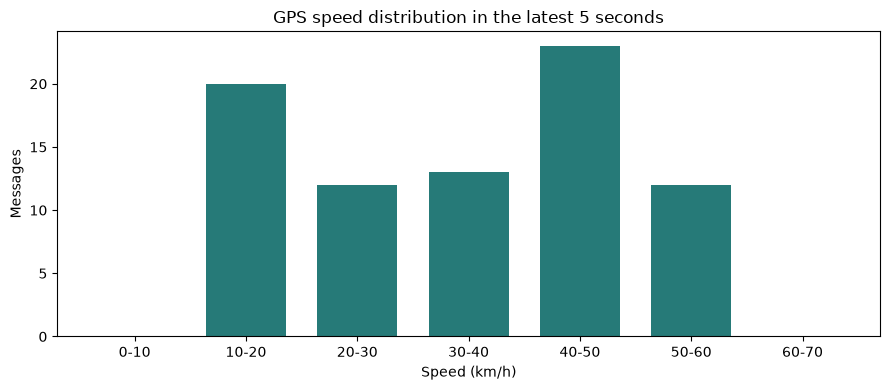

In [ ]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import time

if "window_query" in globals() and window_query.isActive:
    window_query.stop()

speed_bins = (
    raw_stream
    .select(
        F.col("timestamp"),
        F.get_json_object(F.col("value").cast("string"), "$.speed_kmh")
        .cast("double")
        .alias("speed_kmh"),
    )
    .filter(F.col("speed_kmh").isNotNull())
    .withColumn("speed_bin", (F.floor(F.col("speed_kmh") / 10) * 10).cast("int"))
    .groupBy(F.window("timestamp", "5 seconds", "1 second"), "speed_bin")
    .count()
    .select(
        F.col("window.start").alias("window_start"),
        "speed_bin",
        "count",
    )
)

window_query = (
    speed_bins.writeStream
    .format("memory")
    .queryName("gps_speed_bins")
    .outputMode("complete")
    .trigger(processingTime="1 second")
    .start()
)

bin_starts = list(range(0, 61, 10))
bin_labels = [f"{start}-{start + 10}" for start in bin_starts]
deadline = time.monotonic() + 30

try:
    pdf = spark.createDataFrame([], "window_start timestamp, speed_bin int, count long").toPandas()
    while time.monotonic() < deadline:
        pdf = spark.sql(
            """
            SELECT window_start, speed_bin, count
            FROM gps_speed_bins
            WHERE window_start = (SELECT MAX(window_start) FROM gps_speed_bins)
            ORDER BY speed_bin
            """
        ).toPandas()
        if not pdf.empty:
            break
        time.sleep(1)

    if pdf.empty:
        print("No GPS messages received after waiting 30 seconds. Check that the generator and stream are running.")
    else:
        counts = (
            pdf.set_index("speed_bin")["count"]
            .reindex(bin_starts, fill_value=0)
        )
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.bar(bin_labels, counts.values, color="#267a78", width=0.72)
        ax.set_title("GPS speed distribution in the latest 5 seconds")
        ax.set_xlabel("Speed (km/h)")
        ax.set_ylabel("Messages Count")
        ax.set_ylim(bottom=0)
        fig.tight_layout()
        plt.show()
finally:
    if window_query.isActive:
        window_query.stop()